# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

Ответ: Обучение проходило на NVIDIA GeForce RTX 4060 Laptop GPU. Основная модель BERT-Mini (Apache 2.0), основной корпус WNUT-17 (CC BY 4.0). Выполнены разделы 1–5 и бонусы 6.1–6.5. Для нового теста в 6.1 взяты английские предложения Tatoeba (CC0).

Использованы шаблон задания, [BERT-Mini](https://huggingface.co/google/bert_uncased_L-4_H-256_A-4), [BERT-Tiny](https://huggingface.co/google/bert_uncased_L-2_H-128_A-2), [статья о предобучении](https://arxiv.org/abs/1908.08962), [данные WNUT-17](https://github.com/leondz/emerging_entities_17), [правила разметки WNUT](https://aclanthology.org/W17-4418/) и [источник предложений Tatoeba](https://tatoeba.org/en/downloads).

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
torch.set_num_threads(min(2, os.cpu_count() or 1))
datasets.disable_progress_bars()

E:\projects\DL\hw1_students\hw1_students\.hw2_work\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1125 00:31:06.858000 29244 torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


torch 2.11.0+cu126, transformers 5.22.1, datasets 5.1.0


CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda NVIDIA GeForce RTX 4060 Laptop GPU


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.1', '6.2', '6.3', '6.4', '6.5'}
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'google/bert_uncased_L-4_H-256_A-4'
REVISION = '387825ce42dbb39b87911cdf8e383ee3b25184f8'
TOKENIZER_KWARGS = {}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    google/bert_uncased_L-4_H-256_A-4
revision: 387825ce42dbb39b87911cdf8e383ee3b25184f8
license:  apache-2.0
language: None
updated:  2021-05-19 17:30:27+00:00
weights:  {'pytorch_model.bin': '43 MB'}


BertTokenizer vocab size 30522
['п', '##е', '##т', '##р', 'и', '##л', '##ь', '##и', '##ч', 'ч', '##а', '##и', '##к', '##ов', '##с', '##к', '##ии', 'р', '##о', '##д', '##и', '##л', '##с', '##я', 'в', 'в', '##о', '##т', '##к', '##и', '##н', '##с', '##к', '##е']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

Ответ: BERT-Mini подходит для английского текста и быстро обучается на ноутбуке. У него 4 слоя и около 11 млн параметров, лицензия Apache 2.0. При предобучении на BookCorpus и английской Википедии он научился учитывать контекст, но теряет регистр, который помогает узнавать имена. У английского BERT-Base-Cased регистр сохраняется, зато 12 слоёв и около 110 млн параметров делают его дороже в обучении. На MNLI-m в карточках указаны 74,8% у Mini и 84,6% у Base-Cased. Для NER нужны отдельные измерения. Хэш версии фиксирует словарь, конфигурацию и веса, которые иначе могут измениться на Hub. [BERT-Base-Cased](https://huggingface.co/google-bert/bert-base-cased).

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

{'model_type': 'bert', 'vocab_size': 30522, 'hidden_size': 256, 'num_hidden_layers': 4, 'num_attention_heads': 4, 'intermediate_size': 1024, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    base = model.base_model
    stack = base.encoder.layer if hasattr(base, 'encoder') else base.transformer.layer

    def count(module):
        return sum(p.numel() for p in module.parameters())

    layers = [count(layer) for layer in stack]
    embeddings, encoder, head = count(base.embeddings), sum(layers), count(model.classifier)
    return dict(embeddings=embeddings, encoder=encoder, head=head,
                other=count(model) - embeddings - encoder - head, layers=layers)

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings     7,945,728   71.5%
encoder        3,159,040   28.4%
head               1,799    0.0%
other                  0    0.0%
total         11,106,567
per layer: [789760, 789760, 789760, 789760]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)
print('input_ids', tuple(enc.input_ids.shape), 'attention_mask', tuple(enc.attention_mask.shape))
print('hidden_states', [tuple(state.shape) for state in out.hidden_states])
print('logits', tuple(out.logits.shape))

input_ids (2, 32) attention_mask (2, 32)
hidden_states [(2, 32, 256), (2, 32, 256), (2, 32, 256), (2, 32, 256), (2, 32, 256)]
logits (2, 32, 7)


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 250: 14.9 ms на NVIDIA GeForce RTX 4060 Laptop GPU


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

Ответ: В батче два предложения. После разбиения слов на части, добавления служебных токенов и выравнивания по длине вход и маска имеют форму (2, 32). Эмбеддинги и каждый из четырёх слоёв выдают (2, 32, 256). На эмбеддинги приходится 7 945 728 параметров, или 71,5%. Один только словарь хранит 30 522 вектора длины 256. Токены обмениваются информацией в слоях внимания. Голова отдельно для каждой позиции выдаёт 7 оценок в примере, поэтому на выходе (2, 32, 7). В основной задаче тегов 13.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# Три примера исходного формата WikiANN ru из шаблона.
from huggingface_hub import hf_hub_download

example_file = hf_hub_download('unimelb-nlp/wikiann', 'ru/validation-00000-of-00001.parquet',
                               repo_type='dataset', revision='f0a3be6dc5564c0cc4150bb660144800a1f539d4')
example = load_dataset('parquet', data_files=example_file, split='train[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
from urllib.request import urlopen
from hashlib import sha256
from datasets import Dataset

DATASET_ID, DATASET_CONFIG = 'leondz/emerging_entities_17', None
DATA_REV = 'e52a2d2a71ac1a051ca2d532eef28653c5c02603'
FILES = {
    'train': ('wnut17train.conll', '731820e13f71af324c6b55a1575ec2ce59fbaa2a0806f8f0400b98d56cd6a7a5'),
    'validation': ('emerging.dev.conll', 'e053b752b8155113ca66e7db08af5f2f5f43ab993694e4774f1ec5bad42312d8'),
    'test': ('emerging.test.annotated', '2aa79b764e56ec9264a1b30fdd9b70195bd00ff400b62edd8f399d5f13c178f0'),
}
types = ['corporation', 'creative-work', 'group', 'location', 'person', 'product']
LABEL_NAMES = ['O'] + [f'{prefix}-{kind}' for kind in types for prefix in ('B', 'I')]
tag_ids = {name: i for i, name in enumerate(LABEL_NAMES)}


def read_conll(filename, checksum):
    path = Path('data/wnut17') / filename
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists() or sha256(path.read_bytes()).hexdigest() != checksum:
        url = f'https://raw.githubusercontent.com/{DATASET_ID}/{DATA_REV}/{filename}'
        with urlopen(url, timeout=60) as response:
            content = response.read()
        if sha256(content).hexdigest() != checksum:
            raise ValueError(f'Контрольная сумма не совпала: {filename}')
        path.write_bytes(content)

    records, words, labels = [], [], []
    for line in path.read_text(encoding='utf-8-sig').splitlines() + ['']:
        if line.strip():
            word, tag = line.rsplit('\t', 1)
            words.append(word)
            labels.append(tag_ids[tag])
        elif words:
            records.append({'tokens': words, 'ner_tags': labels})
            words, labels = [], []
    return Dataset.from_list(records)


raw = DatasetDict({split: read_conll(*files) for split, files in FILES.items()})
print(raw)
print(LABEL_NAMES)

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 3394
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1009
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1287
    })
})
['O', 'B-corporation', 'I-corporation', 'B-creative-work', 'I-creative-work', 'B-group', 'I-group', 'B-location', 'I-location', 'B-person', 'I-person', 'B-product', 'I-product']


In [14]:
def length_summary(lengths):
    return dict(min=min(lengths), median=float(np.median(lengths)), p90=float(np.percentile(lengths, 90)),
                max=max(lengths), mean=round(float(np.mean(lengths)), 2))


stats = {}
for split, ds in raw.items():
    span_lengths = {kind: [] for kind in types}
    sentence_lengths = []
    for row in ds:
        sentence_lengths.append(len(row['tokens']))
        last_type = None
        for tag_id in row['ner_tags']:
            tag = LABEL_NAMES[tag_id]
            if tag == 'O':
                last_type = None
                continue
            prefix, kind = tag.split('-', 1)
            if prefix == 'I' and kind == last_type:
                span_lengths[kind][-1] += 1
            else:
                span_lengths[kind].append(1)
            last_type = kind
    lengths = [n for lengths_of_type in span_lengths.values() for n in lengths_of_type]
    stats[split] = dict(sentences=len(ds), counts={k: len(v) for k, v in span_lengths.items()},
                        sentence_words=length_summary(sentence_lengths), span_words=length_summary(lengths),
                        span_hist=dict(sorted(collections.Counter(lengths).items())),
                        type_mean={k: round(float(np.mean(v)), 2) if v else 0.0 for k, v in span_lengths.items()})
print('тип                 train   val  test')
for kind in types:
    print(f'{kind:17} ' + ' '.join(f'{stats[s]["counts"][kind]:5d}' for s in raw))
for split, summary in stats.items():
    print(split, 'слова в предложении:', summary['sentence_words'])
    print('  слова в спане:', summary['span_words'], 'длина → число:', summary['span_hist'])
    print('  средняя длина по типу:', summary['type_mean'])

тип                 train   val  test
corporation         221    34    66
creative-work       140   105   142
group               264    39   165
location            548    74   150
person              660   470   429
product             142   114   127
train слова в предложении: {'min': 1, 'median': 18.0, 'p90': 28.0, 'max': 41, 'mean': 18.48}
  слова в спане: {'min': 1, 'median': 1.0, 'p90': 3.0, 'max': 14, 'mean': 1.6} длина → число: {1: 1182, 2: 587, 3: 131, 4: 34, 5: 16, 6: 9, 7: 8, 9: 2, 10: 3, 11: 1, 12: 1, 14: 1}
  средняя длина по типу: {'corporation': 1.21, 'creative-work': 2.47, 'group': 1.57, 'location': 1.45, 'person': 1.51, 'product': 2.43}
validation слова в предложении: {'min': 1, 'median': 13.0, 'p90': 30.0, 'max': 82, 'mean': 15.59}
  слова в спане: {'min': 1, 'median': 1.0, 'p90': 3.0, 'max': 10, 'mean': 1.5} длина → число: {1: 556, 2: 193, 3: 65, 4: 12, 5: 3, 6: 4, 8: 2, 10: 1}
  средняя длина по типу: {'corporation': 1.35, 'creative-work': 2.27, 'group': 1.64, 'loc

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

Ответ: WNUT-17 состоит из английских сообщений из Twitter, YouTube, Reddit и Stack Overflow. Новые тексты размечали по три человека, после объединения меток авторы проверяли результат вручную. Лицензия корпуса CC BY 4.0. В обучающей, валидационной и тестовой выборках 3 394, 1 009 и 1 287 предложений. Числа по всем шести типам приведены в таблице выше. В обучении чаще всего встречаются люди (660), реже всего произведения (140) и продукты (142). Названия произведений и продуктов занимают в среднем около 2,4 слова при среднем 1,6 по всем типам. В коротких сообщениях труднее понять, где заканчивается такое название.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    spans = []
    start, active = 0, None
    for i, tag in enumerate(tags):
        if tag == 'O':
            if active is not None:
                spans.append((start, i, active))
            active = None
            continue
        prefix, kind = tag.split('-', 1)
        if prefix not in ('B', 'I') or not kind:
            raise ValueError(f'Неизвестный BIO-тег: {tag}')
        if prefix == 'B' or kind != active:
            if active is not None:
                spans.append((start, i, active))
            start, active = i, kind
    if active is not None:
        spans.append((start, len(tags), active))
    return spans


def spans_to_bio(spans, n_words):
    if n_words < 0:
        raise ValueError('Длина предложения должна быть неотрицательной')
    tags = ['O'] * n_words
    for start, end, kind in spans:
        if not 0 <= start < end <= n_words or not kind or any(t != 'O' for t in tags[start:end]):
            raise ValueError(f'Некорректный или пересекающийся спан: {(start, end, kind)}')
        tags[start:end] = ['B-' + kind] + ['I-' + kind] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    aligned, seen = [], set()
    for word in word_ids:
        if word is None:
            aligned.append(-100)
        elif word not in seen:
            seen.add(word)
            aligned.append(word_labels[word])
        elif b_to_i is not None:
            aligned.append(b_to_i.get(word_labels[word], word_labels[word]))
        else:
            aligned.append(-100)
    return aligned

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
roundtrip_changes = {}
for split, ds in raw.items():
    path = Path('data') / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as stream:
        for row in ds:
            tags = [LABEL_NAMES[i] for i in row['ner_tags']]
            record = {'tokens': row['tokens'], 'spans': bio_to_spans(tags)}
            stream.write(json.dumps(record, ensure_ascii=False) + '\n')
    changed = 0
    with path.open(encoding='utf-8') as stream:
        for row, line in zip(ds, stream, strict=True):
            saved = json.loads(line)
            assert saved['tokens'] == row['tokens']
            restored = spans_to_bio(saved['spans'], len(saved['tokens']))
            original = [LABEL_NAMES[i] for i in row['ner_tags']]
            assert bio_to_spans(restored) == bio_to_spans(original)
            changed += restored != original
    roundtrip_changes[split] = changed
    print(f'{split}: проверено {len(ds)}, BIO изменилось в {changed} предложениях')

shown = 0
for row in raw['train']:
    tags = [LABEL_NAMES[i] for i in row['ner_tags']]
    spans = bio_to_spans(tags)
    if spans and shown < 2:
        print(list(zip(row['tokens'], tags)))
        print([(a, b, k, ' '.join(row['tokens'][a:b])) for a, b, k in spans])
        shown += 1
    if shown == 2:
        break

train: проверено 3394, BIO изменилось в 0 предложениях
validation: проверено 1009, BIO изменилось в 0 предложениях


test: проверено 1287, BIO изменилось в 0 предложениях
[('@paulwalk', 'O'), ('It', 'O'), ("'s", 'O'), ('the', 'O'), ('view', 'O'), ('from', 'O'), ('where', 'O'), ('I', 'O'), ("'m", 'O'), ('living', 'O'), ('for', 'O'), ('two', 'O'), ('weeks', 'O'), ('.', 'O'), ('Empire', 'B-location'), ('State', 'I-location'), ('Building', 'I-location'), ('=', 'O'), ('ESB', 'B-location'), ('.', 'O'), ('Pretty', 'O'), ('bad', 'O'), ('storm', 'O'), ('here', 'O'), ('last', 'O'), ('evening', 'O'), ('.', 'O')]
[(14, 17, 'location', 'Empire State Building'), (18, 19, 'location', 'ESB')]
[('From', 'O'), ('Green', 'O'), ('Newsfeed', 'O'), (':', 'O'), ('AHFA', 'B-group'), ('extends', 'O'), ('deadline', 'O'), ('for', 'O'), ('Sage', 'O'), ('Award', 'O'), ('to', 'O'), ('Nov', 'O'), ('.', 'O'), ('5', 'O'), ('http://tinyurl.com/24agj38', 'O')]
[(4, 5, 'group', 'AHFA')]


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 3394
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1009
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1287
    })
})
ENTITY_TYPES ['corporation', 'creative-work', 'group', 'location', 'person', 'product']


train: проверено 3394 предложений, обрезано по MAX_LENGTH 0, слов без сабвордов или за обрезкой 0
[CLS]            None  -100
@                   0  O
paul                0  -100
##walk              0  -100
it                  1  O
'                   2  O
s                   2  -100
the                 3  O
view                4  O
from                5  O
where               6  O
i                   7  O
'                   8  O
m                   8  -100
living              9  O
for                10  O
two                11  O
weeks              12  O
.                  13  O
empire             14  B-location
state              15  I-location
building           16  I-location
=                  17  O
es                 18  B-location
##b                18  -100
.                  19  O
pretty             20  O
bad                21  O
storm              22  O
here               23  O
last               24  O
evening            25  O
.                  26  O
[SEP]            None  

In [19]:
# Ровно MAX_LENGTH и фактическое усечение различаются на предложениях ровно заданной длины.
true_clipped = exact_limit = 0
for start in range(0, len(data['train']), 64):
    batch = data['train'][start:start + 64]['tokens']
    ids = tokenizer(batch, is_split_into_words=True, truncation=False)['input_ids']
    true_clipped += sum(len(row) > MAX_LENGTH for row in ids)
    exact_limit += sum(len(row) == MAX_LENGTH for row in ids)
assert true_clipped + exact_limit == n_truncated
print(f'Исходная длина: больше {MAX_LENGTH} у {true_clipped}, ровно {MAX_LENGTH} у {exact_limit}')

Исходная длина: больше 128 у 0, ровно 128 у 0


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

Ответ: Метка стоит на первой части слова, чтобы каждое слово учитывалось в обучении один раз. Остальные части и служебные токены получают -100, их функция потерь пропускает. Во всех трёх выборках исходные BIO-теги точно восстановились из спанов. При лимите 128 позиций в train и validation ничего не обрезалось, в test обрезались два предложения. Без единого сабворда осталось 0, 4 и 33 слова соответственно. Два таких слова на тесте входят в сущности, а при оценке автоматически получают O, что ограничивает полноту.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [20]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [21]:
def fit_majority_tagger(tokens_list, tags_list):
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list, strict=True):
        for word, tag in zip(words, tags, strict=True):
            counts[word][tag] += 1
    return {word: tags.most_common(1)[0][0] for word, tags in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(word, 'O') for word in words]

In [22]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_words = list(data['train']['tokens'])
train_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
tagger = fit_majority_tagger(train_words, train_gold)
dictionary_pred = [predict_majority(tagger, ws) for ws in val_tokens]
set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline = {'majority': entity_scores(val_gold, dictionary_pred), 'random_head': entity_scores(val_gold, random_pred)}
print(json.dumps(baseline, indent=2))
print('Частые теги случайной головы:', collections.Counter(t for tags in random_pred for t in tags).most_common(5))
train_surface = {tuple(ws[a:b]) for ws, gold in zip(train_words, train_gold) for a, b, _ in bio_to_spans(gold)}
val_surface = [tuple(ws[a:b]) for ws, gold in zip(val_tokens, val_gold) for a, b, _ in bio_to_spans(gold)]
print('Совпадения текста сущности с train:', sum(s in train_surface for s in val_surface), '/', len(val_surface))
del random_model

{
  "majority": {
    "f1_micro": 0.09641025641025643,
    "f1_macro": 0.044479780407126045,
    "precision": 0.3381294964028777,
    "recall": 0.056220095693779906
  },
  "random_head": {
    "f1_micro": 0.004902711812471272,
    "f1_macro": 0.006115130381561435,
    "precision": 0.002619086593550499,
    "recall": 0.03827751196172249
  }
}
Частые теги случайной головы: [('B-location', 5005), ('O', 2112), ('I-corporation', 1913), ('B-creative-work', 1768), ('I-product', 1087)]
Совпадения текста сущности с train: 0 / 836


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

Ответ: На валидации F1 словаря равен 0,0964, полнота всего 0,0562. Из 836 названий ни одно целиком не встречалось в разметке train с тем же регистром. Иногда словарь угадывает метку отдельного знакомого слова, а незнакомым словам всегда ставит O. У случайной головы F1 равен 0,0049. Энкодер уже учитывает контекст, но голова ещё не выучила, каким признакам соответствуют BIO-теги.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [23]:
LR = 2e-4
BATCH_SIZE = 16
train_peak_mib = {}


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    tok = tok or tokenizer
    model.base_model.requires_grad_(not freeze_encoder)
    model.to(device)
    collate = DataCollatorForTokenClassification(tok, pad_to_multiple_of=8 if device.type == 'cuda' else None)
    generator = torch.Generator().manual_seed(SEED)
    train_loader = torch.utils.data.DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=generator,
                                              collate_fn=collate, num_workers=0)
    val_loader = torch.utils.data.DataLoader(eval_ds, batch_size=batch_size, collate_fn=collate, num_workers=0)
    # Частичный противовес частому фону. Частоты берутся только из обучающих меток первых сабвордов.
    counts = collections.Counter(tag for row in train_ds['labels'] for tag in row if tag != -100)
    o_id = label2id['O']
    n_o = counts[o_id]
    n_entity = sum(counts.values()) - n_o
    o_weight = min(1.0, math.sqrt(n_entity / n_o)) if n_entity and n_o else 1.0
    class_weights = torch.ones(len(LABEL_NAMES), device=device)
    class_weights[o_id] = o_weight
    print(f'Обучающие слова: фон {n_o}, сущности {n_entity}; вес O = {o_weight:.3f}')
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW([{'params': [p for p in params if p.ndim > 1], 'weight_decay': 0.01},
                                  {'params': [p for p in params if p.ndim <= 1], 'weight_decay': 0.0}], lr=lr)
    steps = epochs * len(train_loader)
    scheduler = transformers.get_linear_schedule_with_warmup(optimizer, math.ceil(0.10 * steps), steps)
    use_fp16 = device.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_fp16)
    log_every = max(1, steps // 10)

    def batch_loss(batch):
        labels = batch['labels']
        n_o = int((labels == o_id).sum())
        mass = int((labels != -100).sum()) - n_o + n_o * o_weight
        inputs = {key: value.to(device) for key, value in batch.items() if key != 'labels'}
        with torch.autocast(device_type=device.type, enabled=use_fp16):
            scores = model(**inputs).logits
            loss = torch.nn.functional.cross_entropy(scores.float().transpose(1, 2), labels.to(device),
                                                     weight=class_weights, ignore_index=-100)
        return loss, mass

    if use_fp16:
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    history, step, token_count, loss_sum = [], 0, 0, 0.0
    model.train()
    for _ in range(epochs):
        for batch in train_loader:
            step += 1
            optimizer.zero_grad(set_to_none=True)
            loss, n = batch_loss(batch)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scale_before = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            if scaler.get_scale() >= scale_before:
                scheduler.step()
            loss_sum += float(loss.detach()) * n
            token_count += n
            if step % log_every == 0 or step == steps:
                model.eval()
                val_sum, val_tokens_seen = 0.0, 0
                with torch.inference_mode():
                    for val_batch in val_loader:
                        val_loss, nv = batch_loss(val_batch)
                        val_sum += float(val_loss) * nv
                        val_tokens_seen += nv
                history.extend([{'step': step, 'loss': loss_sum / token_count},
                                {'step': step, 'eval_loss': val_sum / val_tokens_seen}])
                token_count, loss_sum = 0, 0.0
                model.train()
    if use_fp16:
        torch.cuda.synchronize()
        train_peak_mib[out_dir] = round(torch.cuda.max_memory_allocated() / 2**20, 1)
    model.eval()
    return history, time.perf_counter() - start

Обучающие слова: фон 59570, сущности 3160; вес O = 0.230


обучение: 30.4 c на NVIDIA GeForce RTX 4060 Laptop GPU, 3394 предложений, 3 эпох(а)


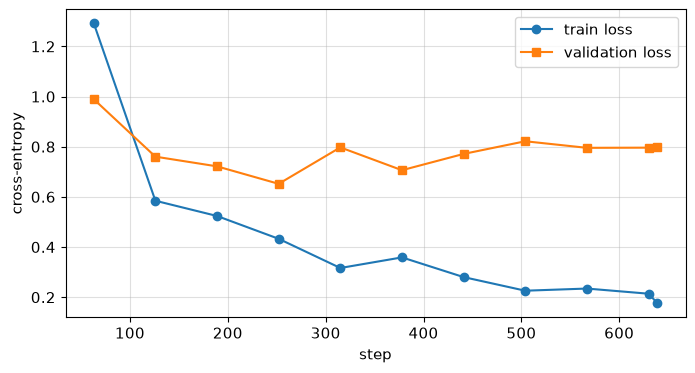

In [24]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

Ответ: Для маленького BERT взят шаг AdamW 0,0002, с разогревом на первых 10% шагов и линейным снижением дальше. Батч из 16 примеров и FP16 экономят память, weight decay 0,01 ограничивает рост весов. Из 62 730 обучающих слов только 3 160 входят в сущности, поэтому у фона вес 0,230, у остальных тегов 1. Три эпохи на RTX 4060 заняли 30,4 с. На валидации самая низкая ошибка была на шаге 252 (0,652), а к шагу 639 она выросла до 0,798, хотя на train снизилась до 0,176. Я бы попробовал раннюю остановку.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [25]:
def token_f1(gold, pred):
    tp, n_gold, n_pred = 0, 0, 0
    for gold_tags, pred_tags in zip(gold, pred, strict=True):
        for truth, guess in zip(gold_tags, pred_tags, strict=True):
            n_gold += truth != 'O'
            n_pred += guess != 'O'
            tp += truth != 'O' and truth == guess
    return 2 * tp / (n_gold + n_pred) if n_gold + n_pred else 0.0

In [26]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

def score_split(gold, pred):
    report = classification_report(gold, pred, output_dict=True, zero_division=0)
    per_type = {k: report[k] for k in ENTITY_TYPES if k in report}
    print(classification_report(gold, pred, digits=4, zero_division=0))
    result = dict(**entity_scores(gold, pred), token_f1=token_f1(gold, pred), per_type=per_type)
    print('token F1:', round(result['token_f1'], 4))
    return result


test_tokens = list(data['test']['tokens'])
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
val_pred, val_probs = predict_word_tags(model, val_tokens, return_probs=True)
print('validation')
val_scores = score_split(val_gold, val_pred)
print('test')
test_pred = predict_word_tags(model, test_tokens)
final = score_split(test_gold, test_pred)

validation


               precision    recall  f1-score   support

  corporation     0.1096    0.2353    0.1495        34
creative-work     0.0222    0.0095    0.0133       105
        group     0.1429    0.1795    0.1591        39
     location     0.4778    0.5811    0.5244        74
       person     0.6794    0.6043    0.6396       470
      product     0.1154    0.0526    0.0723       114

    micro avg     0.4801    0.4175    0.4466       836
    macro avg     0.2579    0.2770    0.2597       836
 weighted avg     0.4539    0.4175    0.4311       836

token F1: 0.4701
test


               precision    recall  f1-score   support

  corporation     0.1146    0.3333    0.1705        66
creative-work     0.0877    0.0352    0.0503       142
        group     0.1667    0.0848    0.1124       165
     location     0.4167    0.5333    0.4678       150
       person     0.6288    0.5291    0.5747       429
      product     0.1325    0.0866    0.1048       127

    micro avg     0.3705    0.3327    0.3506      1079
    macro avg     0.2578    0.2671    0.2468      1079
 weighted avg     0.3676    0.3327    0.3401      1079

token F1: 0.3728


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

Ответ: На тесте хуже всего распознаются названия произведений (F1 0,0503). В train таких спанов всего 140, и часто это несколько обычных слов или имя персонажа внутри названия. Micro-F1 равен 0,3506, macro-F1 0,2468. При подсчёте macro-F1 редкие классы весят столько же, сколько частый класс person, поэтому итог ниже. F1 по словам выше (0,3728). Часть длинного названия можно угадать, даже если пропущено последнее слово. Если нужно извлечь название целиком, полезнее смотреть F1 по сущностям.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [27]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    result, touched = [], set()
    for gold in gold_spans:
        start, end, kind = gold
        overlaps = []
        for i, pred in enumerate(pred_spans):
            overlap = min(end, pred[1]) - max(start, pred[0])
            if overlap > 0:
                touched.add(i)
                overlaps.append((pred == gold, pred[2] == kind, overlap, -i, pred))
        if not overlaps:
            result.append(('missed', gold, None))
            continue
        exact, same_type, _, _, pred = max(overlaps)
        category = 'correct' if exact else 'boundary' if same_type else 'type'
        result.append((category, gold, pred))
    result.extend(('spurious', None, pred) for i, pred in enumerate(pred_spans) if i not in touched)
    return result

In [28]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

counts = collections.Counter()
examples = collections.defaultdict(list)
for index, (gold_tags, pred_tags) in enumerate(zip(val_gold, val_pred, strict=True)):
    for category, truth, guess in categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags)):
        counts[category] += 1
        if category != 'correct' and len(examples[category]) < 3:
            examples[category].append((index, truth, guess))
errors = {name: counts[name] for name in ERROR_CATEGORIES}
error_total = sum(errors.values()) - errors['correct']
for name, count in errors.items():
    share = f'{count / error_total:.1%} ошибок' if name != 'correct' and error_total else ''
    print(f'{name:9} {count:5}  {share}')


def describe_span(span, words):
    if span is None:
        return '∅'
    start, end, kind = span
    return f'[{start},{end}) {kind}: {" ".join(words[start:end])}'


for category, items in examples.items():
    for index, truth, guess in items:
        words = val_tokens[index]
        print(f'\n{category} | validation[{index}] | {" ".join(words)}')
        print('  разметка:', describe_span(truth, words), '| прогноз:', describe_span(guess, words))

correct     349  
boundary     78  12.1% ошибок
type        109  17.0% ошибок
missed      300  46.7% ошибок
spurious    155  24.1% ошибок

boundary | validation[1] | You should ' ve stayed on Redondo Beach Blvd . you were in the borderlines of Gardena / Compton
  разметка: [16,17) location: Gardena | прогноз: [16,18) location: Gardena /

boundary | validation[22] | hhaahaa 😂 😂 martin short great !
  разметка: [3,5) person: martin short | прогноз: [3,4) person: martin

boundary | validation[35] | That rick roll was so good XD
  разметка: [1,2) person: rick | прогноз: [1,3) person: rick roll

spurious | validation[1] | You should ' ve stayed on Redondo Beach Blvd . you were in the borderlines of Gardena / Compton
  разметка: ∅ | прогноз: [14,15) location: borderlines

spurious | validation[2] | All I ' ve been doing is BINGE watching Rick and Morty 😂
  разметка: ∅ | прогноз: [7,8) person: BINGE

spurious | validation[5] | trump is the Kremlin ' s boy
  разметка: ∅ | прогноз: [3,4) person

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

Ответ: Из 642 ошибок на валидации 300 полных пропусков (46,7%). Например, модель пропустила имя kaite и продукт HA 5. Для обучения я бы добавил короткие имена и названия продуктов с цифрами. При ошибках границы к Gardena присоединилась косая черта, а у martin short потерялась фамилия. В сообщении о сериале модель приняла Rick за человека внутри названия Rick and Morty, а слово BINGE выделила как отдельное имя. Спорный пример есть в validation[83]. Там оба слова sunil grover получили O, хотя по контексту это похоже на имя человека.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [29]:
ABLATION = 'freeze'
model.cpu()
set_seed(SEED)
frozen = make_model()
_, freeze_seconds = train_ner(frozen, tokenized['train'], tokenized['validation'], freeze_encoder=True,
                              out_dir='runs/freeze')
freeze_scores = entity_scores(val_gold, predict_word_tags(frozen, val_tokens))
ablation = dict(setting=ABLATION, split='validation',
                full=dict(f1_micro=val_scores['f1_micro'], seconds=train_seconds,
                          trainable=sum(p.numel() for p in model.parameters() if p.requires_grad)),
                freeze=dict(f1_micro=freeze_scores['f1_micro'], seconds=freeze_seconds,
                            trainable=sum(p.numel() for p in frozen.parameters() if p.requires_grad)))
print(json.dumps(ablation, indent=2))
del frozen

Обучающие слова: фон 59570, сущности 3160; вес O = 0.230


{
  "setting": "freeze",
  "split": "validation",
  "full": {
    "f1_micro": 0.44657709532949447,
    "seconds": 30.439887999993516,
    "trainable": 11108109
  },
  "freeze": {
    "f1_micro": 0.0,
    "seconds": 19.073216799995862,
    "trainable": 3341
  }
}


**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

Ответ: При заморозке число обучаемых параметров сократилось с 11 108 109 до 3 341. Обучение заняло 19,1 с вместо 30,4 с, но F1 на валидации упал с 0,4466 до 0,0000. За три эпохи голова на фиксированных признаках не научилась точно находить сущности. Для проверки я бы повторил сравнение с несколькими случайными инициализациями.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

Ответ: На валидации словарь дал F1 0,0964, а дообученный BERT-Mini 0,4466. На тесте у модели F1 0,3506, точность 0,3705 и полнота 0,3327. Имена людей она находила лучше всего, названия произведений часто пропускала. В обучении было только 140 примеров произведений, и даже ошибка в одном слове меняла границу всего названия. После шага 252 ошибка на валидации уже не опускалась до своего минимума. Дальше я бы проверил раннюю остановку и модель с учётом регистра на тех же сплитах.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [30]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "google/bert_uncased_L-4_H-256_A-4", "revision": "387825ce42dbb39b87911cdf8e383ee3b25184f8", "dataset": "leondz/emerging_entities_17", "classes": ["corporation", "creative-work", "group", "location", "person", "product"], "n_train": 3394, "n_val": 1009, "n_test": 1287, "params_total": 11108109, "ablation": {"setting": "freeze", "split": "validation", "full": {"f1_micro": 0.44657709532949447, "seconds": 30.439887999993516, "trainable": 11108109}, "freeze": {"f1_micro": 0.0, "seconds": 19.073216799995862, "trainable": 3341}}, "errors": {"correct": 349, "boundary": 78, "
final F1 micro 0.3506


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

Правила разметки

Предложения взяты из [английской выгрузки Tatoeba CC0](https://downloads.tatoeba.org/exports/per_language/eng/eng_sentences_CC0.tsv.bz2). В файле annotations.jsonl сохранены исходная строка, слова, границы сущностей и номер предложения. По номеру можно открыть [оригинал](https://tatoeba.org/en/sentences/show/11752440). Примеры подбирались до получения прогнозов: в набор вошли многословные имена и названия, слова с разными значениями и предложения без имён.

1. Находим имя человека или персонажа (person), место (location), компанию (corporation), товар (product), произведение (creative-work) либо коллектив или некоммерческую организацию (group). Тип определяет контекст предложения.
2. Отмечаем полное имя. Артикль включаем, если он входит в название. Внутренний дефис или двоеточие оставляем внутри спана. Притяжательное окончание и знак в конце предложения в спан не входят.
3. Границы считаем по словам с нуля, правая граница исключается. Вне спанов ставим O, в начале сущности B, на продолжении I. У неназванной группы или обычного предмета все слова получают O.

In [31]:
if '6.1' in BONUS_TASKS:
    import unicodedata

    def sentence_key(words):
        text = unicodedata.normalize('NFKC', ''.join(words)).casefold()
        return ''.join(ch for ch in text if ch.isalnum())

    path = ARTIFACTS / 'annotations.jsonl'
    with path.open(encoding='utf-8') as stream:
        annotations = [json.loads(line) for line in stream if line.strip()]
    assert len(annotations) >= 50
    assert len({row['sentence_id'] for row in annotations}) == len(annotations)
    wnut_keys = {sentence_key(words) for split in raw.values() for words in split['tokens']}
    keys = [sentence_key(row['tokens']) for row in annotations]
    assert len(set(keys)) == len(keys) and set(keys).isdisjoint(wnut_keys)

    new_rows, support = [], collections.Counter()
    for row in annotations:
        words = row['tokens']
        assert words == re.findall(r'[^\W_]+|[^\w\s]|_+', row['text'])
        spans = [tuple(s) for s in row['spans']]
        assert all(kind in ENTITY_TYPES for _, _, kind in spans)
        tags = spans_to_bio(spans, len(words))
        assert bio_to_spans(tags) == spans
        support.update(kind for _, _, kind in spans)
        new_rows.append({'tokens': words, 'ner_tags': [label2id[tag] for tag in tags]})

    extra_test = Dataset.from_list(new_rows)
    extra_words = list(extra_test['tokens'])
    extra_gold = [[LABEL_NAMES[i] for i in ids] for ids in extra_test['ner_tags']]
    extra_dictionary = [predict_majority(tagger, words) for words in extra_words]
    extra_pred = predict_word_tags(model, extra_words)
    model.cpu()
    extra_scores = entity_scores(extra_gold, extra_pred)
    extra_baseline = entity_scores(extra_gold, extra_dictionary)
    n_empty = sum(not row['spans'] for row in annotations)
    change = extra_scores['f1_micro'] - final['f1_micro']
    metrics['bonus_6_1'] = dict(split='Tatoeba CC0 (separate test)', file=path.as_posix(),
                                sentences=len(extra_test), without_entities=n_empty, support=dict(support),
                                wnut_test_f1=final['f1_micro'], tatoeba_model=extra_scores,
                                tatoeba_dictionary=extra_baseline, delta_f1=change)
    (ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2),
                                           encoding='utf-8')
    print(f'Предложений: {len(extra_test)}, без сущностей: {n_empty}, размеченных сущностей: {sum(support.values())}')
    for kind in ENTITY_TYPES:
        print(f'{kind:14} {support[kind]:3}')
    print(f'Словарь на Tatoeba:     {extra_baseline["f1_micro"]:.4f}')
    print(f'BERT-Mini на WNUT test: {final["f1_micro"]:.4f}')
    print(f'BERT-Mini на Tatoeba:   {extra_scores["f1_micro"]:.4f} (разница {change:+.4f})')

Предложений: 60, без сущностей: 8, размеченных сущностей: 91
corporation     10
creative-work    8
group           13
location        22
person          30
product          8
Словарь на Tatoeba:     0.3151
BERT-Mini на WNUT test: 0.3506
BERT-Mini на Tatoeba:   0.5048 (разница +0.1542)


**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

Ответ: В отдельном тесте 60 английских предложений Tatoeba. В 52 предложениях размечена 91 сущность, остальные восемь целиком получили тег O. Отбор, разметка ассистентом и проверка границ заняли 2 мин 9 с. На Tatoeba у модели F1 0,5048, у словаря 0,3151. На исходном тесте WNUT у той же модели F1 0,3506. На Tatoeba он на 0,1542 выше, но это другая выборка, собранная по типам имён. Тип приходилось выбирать по смыслу. Например, Liverpool в сообщении о дерби обозначает команду, а во фразе об отъезде из Liverpool это город.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [32]:
if '6.2' in BONUS_TASKS:
    TINY_ID = 'google/bert_uncased_L-2_H-128_A-2'
    TINY_REV = '30b0a37ccaaa32f332884b96992754e246e48c5f'
    tiny_tok = AutoTokenizer.from_pretrained(TINY_ID, revision=TINY_REV)
    tiny_data = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                         fn_kwargs={'tok': tiny_tok})
    set_seed(SEED)
    tiny = make_model(TINY_ID, TINY_REV)
    _, tiny_seconds = train_ner(tiny, tiny_data['train'], tiny_data['validation'], tok=tiny_tok, out_dir='runs/tiny')

    def compare_encoder(net, tok, seconds, run):
        net.to(device).eval()
        predict_word_tags(net, val_tokens[:64], tok=tok)
        times = []
        for _ in range(3):
            if device.type == 'cuda':
                torch.cuda.synchronize()
            start = time.perf_counter()
            pred = predict_word_tags(net, val_tokens, tok=tok)
            if device.type == 'cuda':
                torch.cuda.synchronize()
            times.append(time.perf_counter() - start)
        return dict(val_f1=entity_scores(val_gold, pred)['f1_micro'], train_s=seconds,
                    val_inference_s=float(np.median(times)), parameters=sum(p.numel() for p in net.parameters()),
                    weights_mib=sum(p.numel() * p.element_size() for p in net.parameters()) / 2**20,
                    peak_train_cuda_mib=train_peak_mib.get(run))

    comparison = {'Tiny': compare_encoder(tiny, tiny_tok, tiny_seconds, 'runs/tiny')}
    del tiny
    comparison['Mini'] = compare_encoder(model, tokenizer, train_seconds, 'runs/main')
    print(json.dumps(comparison, indent=2))

Обучающие слова: фон 59570, сущности 3160; вес O = 0.230


{
  "Tiny": {
    "val_f1": 0.4328259430840503,
    "train_s": 18.098138900008053,
    "val_inference_s": 0.6174548000126379,
    "parameters": 4371085,
    "weights_mib": 16.674365997314453,
    "peak_train_cuda_mib": 101.2
  },
  "Mini": {
    "val_f1": 0.44657709532949447,
    "train_s": 30.439887999993516,
    "val_inference_s": 0.8571145000023535,
    "parameters": 11108109,
    "weights_mib": 42.37407302856445,
    "peak_train_cuda_mib": 229.6
  }
}


**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

Ответ: На валидации Mini получил F1 0,4466, Tiny 0,4328. У Tiny меньше параметров (4,37 млн против 11,11 млн) и ниже пик памяти тензоров на GPU (101,2 против 229,6 МиБ). Обучение заняло 18,1 с у Tiny и 30,4 с у Mini. Обработка всей валидации вместе с токенизацией заняла 0,617 и 0,857 с соответственно. Для обеих моделей совпадали сплиты, seed, три эпохи, шаг обучения, веса классов, батч и длина входа.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [33]:
if '6.3' in BONUS_TASKS:
    def introduce_typos(sentences, seed):
        rng = random.Random(seed)
        output = []
        for words in sentences:
            altered = []
            for word in words:
                if len(word) >= 4 and word.isalpha() and rng.random() < 0.30:
                    positions = [i for i in range(1, len(word) - 2) if word[i] != word[i + 1]]
                    if positions:
                        i = rng.choice(positions)
                        word = word[:i] + word[i + 1] + word[i] + word[i + 2:]
                altered.append(word)
            output.append(altered)
        return output

    def pieces_per_word(sentences):
        count = 0
        for begin in range(0, len(sentences), 64):
            batch = sentences[begin:begin + 64]
            ids = tokenizer(batch, is_split_into_words=True, add_special_tokens=False)['input_ids']
            count += sum(map(len, ids))
        return count / sum(map(len, sentences))

    shifted = {}
    variants = {'clean': val_tokens, 'lower': [[w.lower() for w in ws] for ws in val_tokens],
                'typos': introduce_typos(val_tokens, SEED)}
    for name, sentences in variants.items():
        assert list(map(len, sentences)) == list(map(len, val_gold))
        pred = val_pred if name == 'clean' else predict_word_tags(model, sentences)
        changed_words = sum(a != b for ws, vs in zip(val_tokens, sentences) for a, b in zip(ws, vs))
        shifted[name] = dict(val_f1=entity_scores(val_gold, pred)['f1_micro'], changed_words=changed_words,
                             subwords_per_word=pieces_per_word(sentences))
    print(json.dumps(shifted, indent=2))

{
  "clean": {
    "val_f1": 0.44657709532949447,
    "changed_words": 0,
    "subwords_per_word": 1.1083709400622894
  },
  "lower": {
    "val_f1": 0.44657709532949447,
    "changed_words": 2556,
    "subwords_per_word": 1.1083709400622894
  },
  "typos": {
    "val_f1": 0.3131381892443839,
    "changed_words": 2041,
    "subwords_per_word": 1.2883111930337507
  }
}


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

Ответ: Нижний регистр изменил 2 556 слов, но F1 остался 0,4466. Токенизатор этой модели сам приводит текст к нижнему регистру. Опечатки в 2 041 словах снизили F1 до 0,3131. После перестановки букв на слово пришлось в среднем 1,288 части вместо 1,108. Так модели труднее узнать знакомое имя и слова рядом с ним.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [34]:
if '6.4' in BONUS_TASKS:
    from torch.ao.quantization import quantize_dynamic

    fp32_model = copy.deepcopy(model.cpu()).float().eval()
    int8_model = quantize_dynamic(fp32_model, {torch.nn.Linear}, dtype=torch.qint8).eval()
    cpu = torch.device('cpu')
    speed_batch = tokenizer(val_tokens[:16], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH,
                            padding=True, return_tensors='pt')

    @torch.inference_mode()
    def time_cpu_forward(models, batch, repetitions=20):
        for net in models:
            for _ in range(4):
                net(**batch)
        times = [[] for _ in models]
        for i in range(repetitions):
            order = range(len(models)) if i % 2 == 0 else reversed(range(len(models)))
            for j in order:
                start = time.perf_counter()
                models[j](**batch)
                times[j].append(1000 * (time.perf_counter() - start))
        return [float(np.mean(values)) for values in times]

    ms = time_cpu_forward([fp32_model, int8_model], speed_batch)
    quantization = {}
    for label, net, mean_ms in zip(('fp32', 'int8'), (fp32_model, int8_model), ms):
        pred = predict_word_tags(net, val_tokens, dev=cpu)
        quantization[label] = dict(mean_ms=mean_ms, val_f1=entity_scores(val_gold, pred)['f1_micro'])
    print('CPU, потоков:', torch.get_num_threads(), 'батч:', tuple(speed_batch.input_ids.shape),
          'бэкенд:', torch.backends.quantized.engine)
    print(json.dumps(quantization, indent=2), 'ускорение:', round(ms[0] / ms[1], 3))
    del fp32_model, int8_model

C:\Users\admin\AppData\Local\Temp\ipykernel_29244\972337709.py:5: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  int8_model = quantize_dynamic(fp32_model, {torch.nn.Linear}, dtype=torch.qint8).eval()


CPU, потоков: 2 батч: (16, 49) бэкенд: onednn
{
  "fp32": {
    "mean_ms": 72.3143599985633,
    "val_f1": 0.44657709532949447
  },
  "int8": {
    "mean_ms": 41.02819499676116,
    "val_f1": 0.46826516220028214
  }
} ускорение: 1.763


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

Ответ: На CPU в два потока один батч из 16 предложений занимал в среднем 72,31 мс в FP32 и 41,03 мс в INT8. Это ускорение в 1,76 раза по 20 измерениям после прогрева. На валидации F1 был 0,4466 до квантизации и 0,4683 после. В INT8 переведены линейные слои, где выполняются матричные умножения. Эмбеддинги остались в FP32, хотя на них приходится около 71,5% параметров, поэтому выигрыш зависит от того, сколько времени занимают именно линейные слои.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

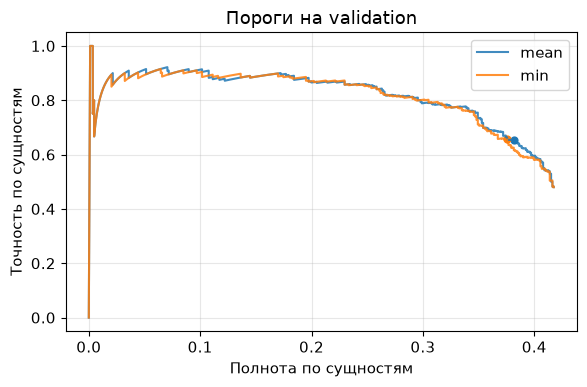

{
  "mean": {
    "best": {
      "threshold": 0.5626175999641418,
      "precision": 0.6550308008213552,
      "recall": 0.3815789473684211,
      "f1": 0.48223733938019653
    },
    "at_zero": {
      "threshold": 0.0,
      "precision": 0.48005502063273725,
      "recall": 0.41746411483253587,
      "f1": 0.4465770953294946
    },
    "gain": 0.03566024405070195
  },
  "min": {
    "best": {
      "threshold": 0.5506891012191772,
      "precision": 0.6555323590814196,
      "recall": 0.37559808612440193,
      "f1": 0.47756653992395437
    },
    "at_zero": {
      "threshold": 0.0,
      "precision": 0.48005502063273725,
      "recall": 0.41746411483253587,
      "f1": 0.4465770953294946
    },
    "gain": 0.030989444594459792
  }
}


In [35]:
if '6.5' in BONUS_TASKS:
    def threshold_curve(gold, pred, probs, aggregate):
        # Порог фильтрует уже собранные спаны. У всех равных оценок решение одно.
        scores = []
        n_gold = 0
        for gold_tags, pred_tags, word_probs in zip(gold, pred, probs, strict=True):
            true_spans = set(bio_to_spans(gold_tags))
            n_gold += len(true_spans)
            for span in bio_to_spans(pred_tags):
                start, end, _ = span
                scores.append((float(aggregate(word_probs[start:end])), span in true_spans))
        scores.sort(reverse=True)
        points, n, tp = [], 0, 0
        def add_point(threshold):
            points.append(dict(threshold=threshold, precision=tp/n if n else 0.0, recall=tp/n_gold if n_gold else 0.0,
                               f1=2*tp/(n+n_gold) if n+n_gold else 0.0))
        if not scores or scores[0][0] < 1.0:
            add_point(1.0)
        while n < len(scores):
            threshold = scores[n][0]
            while n < len(scores) and scores[n][0] == threshold:
                tp += scores[n][1]
                n += 1
            add_point(threshold)
        if points[-1]['threshold'] != 0.0:
            add_point(0.0)
        return list(reversed(points))

    thresholds = {}
    fig, ax = plt.subplots(figsize=(6, 4))
    for name, aggregate in [('mean', np.mean), ('min', min)]:
        curve = threshold_curve(val_gold, val_pred, val_probs, aggregate)
        assert abs(curve[0]['f1'] - val_scores['f1_micro']) < 1e-9
        assert all(y['recall'] <= x['recall'] for x, y in zip(curve, curve[1:]))
        best = max(curve, key=lambda row: row['f1'])
        thresholds[name] = dict(best=best, at_zero=curve[0], gain=best['f1'] - curve[0]['f1'])
        ax.plot([r['recall'] for r in curve], [r['precision'] for r in curve], label=name, alpha=0.85)
        ax.scatter(best['recall'], best['precision'], s=24)
    ax.set(xlabel='Полнота по сущностям', ylabel='Точность по сущностям', title='Пороги на validation')
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()
    print(json.dumps(thresholds, indent=2))

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

Ответ: На валидации лучший порог по средней вероятности составил 0,56262. F1 вырос с 0,4466 до 0,4822 (+0,0357). При этом точность выросла с 0,4801 до 0,6550, а полнота снизилась с 0,4175 до 0,3816. По минимальной вероятности лучший порог 0,55069, F1 0,4776 (+0,0310). Для минимума достаточно одного неуверенного слова, чтобы отбросить весь спан. Порог только удаляет уже найденные спаны, поэтому повысить полноту он не может.